# 05 - Preprocessing and stratified splits

Build a train-only sklearn pipeline and create a stratified 80/20 holdout plus
stratified 5-fold CV indices.

Pipeline steps (fit on training fold / train split only):
1. Missing indicators for high-signal sparse fields
2. Median imputation
3. Winsorise / cap outliers at training quantiles (1st / 99th)

All features in `train_features.parquet` are numeric (categoricals were
aggregated in Stage 3), so no categorical encoder is needed here.

Split indices are saved for reproducible modelling.

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    HOLDOUT_SIZE,
    ID_COL,
    N_CV_FOLDS,
    RANDOM_SEED,
    SPLIT_INDICES_PATH,
    TARGET_COL,
    TRAIN_FEATURES_PATH,
)
from src.preprocess import (
    HIGH_SIGNAL_MISSING,
    build_preprocess_pipeline,
    feature_columns,
    make_splits,
)

print("seed", RANDOM_SEED, "holdout", HOLDOUT_SIZE, "cv folds", N_CV_FOLDS)
print("features", TRAIN_FEATURES_PATH)

seed 42 holdout 0.2 cv folds 5
features C:\Users\user\Desktop\Credit-Scoring Project\data\processed\train_features.parquet


shape (307507, 52)
target rate 0.0807
n features 52


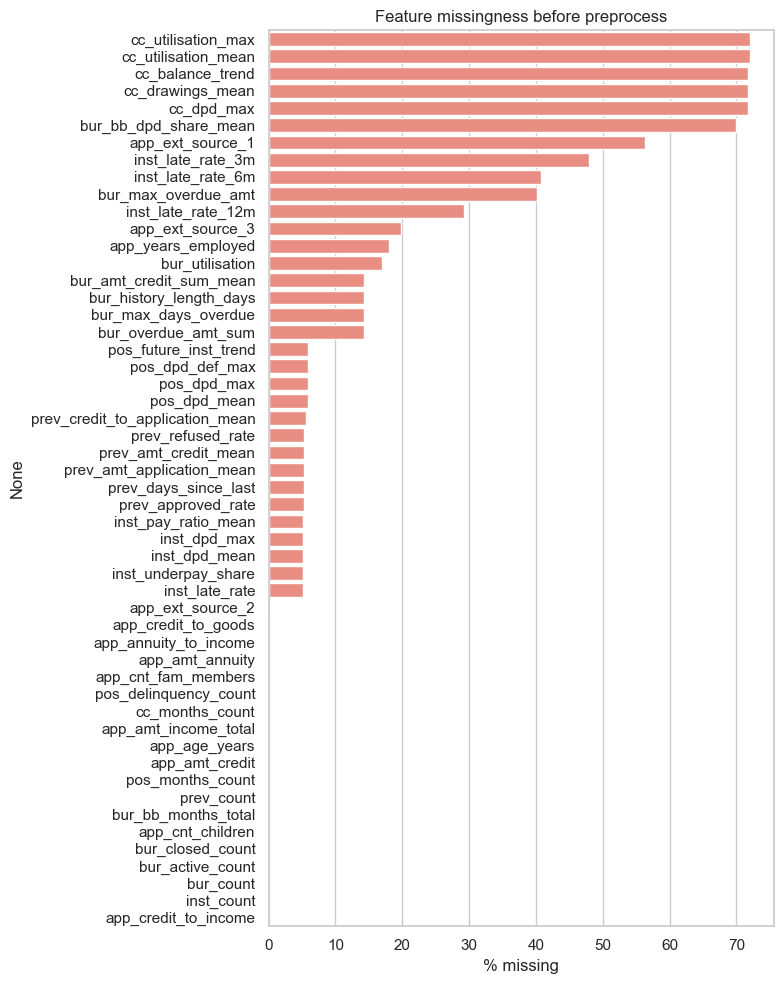

In [2]:
df = pd.read_parquet(TRAIN_FEATURES_PATH)
feature_cols = feature_columns(df)
X = df[feature_cols].copy()
y = df[TARGET_COL].astype(int)
ids = df[ID_COL]

print("shape", X.shape)
print("target rate", round(y.mean(), 4))
print("n features", len(feature_cols))

miss = (X.isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 10))
sns.barplot(x=miss.values, y=miss.index, ax=ax, color="salmon")
ax.set_xlabel("% missing")
ax.set_title("Feature missingness before preprocess")
plt.tight_layout()
plt.show()


## Stratified holdout + CV indices

Holdout is carved first. CV folds are defined **only on the train partition**.

In [3]:
splits = make_splits(y)
train_idx = np.asarray(splits["train_idx"])
holdout_idx = np.asarray(splits["holdout_idx"])
cv_folds = splits["cv_folds"]

print("train", len(train_idx), "holdout", len(holdout_idx))
print("train target rate", round(splits["train_target_rate"], 4))
print("holdout target rate", round(splits["holdout_target_rate"], 4))
for fold in cv_folds:
    va = fold["valid_idx"]
    print(
        f"fold {fold['fold']}: train={len(fold['train_idx'])} valid={len(va)} "
        f"valid_rate={y.iloc[va].mean():.4f}"
    )

assert set(train_idx).isdisjoint(set(holdout_idx))
assert len(set(train_idx) | set(holdout_idx)) == len(df)
print("split integrity ok")


train 246005 holdout 61502
train target rate 0.0807
holdout target rate 0.0807
fold 0: train=196804 valid=49201 valid_rate=0.0807
fold 1: train=196804 valid=49201 valid_rate=0.0807
fold 2: train=196804 valid=49201 valid_rate=0.0807
fold 3: train=196804 valid=49201 valid_rate=0.0807
fold 4: train=196804 valid=49201 valid_rate=0.0807
split integrity ok


## Preprocess transformers (train-fit only)

Use `src.preprocess.build_preprocess_pipeline` (missing flags -> median impute -> p01/p99 cap).


In [4]:
missing_cols = [c for c in HIGH_SIGNAL_MISSING if c in feature_cols]
print("missing-indicator cols:", missing_cols)
preprocess = build_preprocess_pipeline(missing_cols)
preprocess


missing-indicator cols: ['app_ext_source_1', 'app_ext_source_2', 'app_ext_source_3', 'app_years_employed', 'cc_utilisation_mean', 'cc_utilisation_max', 'inst_late_rate', 'inst_late_rate_3m', 'inst_late_rate_6m', 'inst_late_rate_12m', 'bur_utilisation', 'bur_bb_dpd_share_mean', 'prev_refused_rate', 'prev_approved_rate']


,steps,"[('missing_flags', ...), ('impute', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,columns,"['app_ext_source_1', 'app_ext_source_2', ...]"
,lower,0.01
,upper,0.99


## Fit on train only -- before / after checks

train transformed (246005, 66)
holdout transformed (61502, 66)
train remaining NaNs 0
holdout remaining NaNs 0


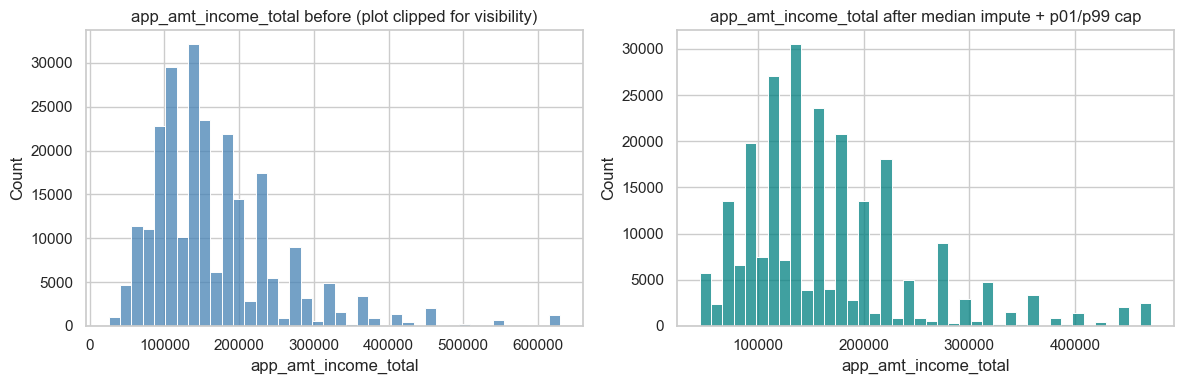

train quantile bounds for app_amt_income_total: [45000.0, 472500.0]


In [5]:
X_train = X.iloc[train_idx].copy()
X_hold = X.iloc[holdout_idx].copy()

preprocess.fit(X_train)
X_train_t = preprocess.transform(X_train)
X_hold_t = preprocess.transform(X_hold)

print("train transformed", X_train_t.shape)
print("holdout transformed", X_hold_t.shape)
print("train remaining NaNs", int(X_train_t.isna().sum().sum()))
print("holdout remaining NaNs", int(X_hold_t.isna().sum().sum()))
assert X_train_t.isna().sum().sum() == 0
assert X_hold_t.isna().sum().sum() == 0

# Show capping effect on a heavy-tailed feature
col = "app_amt_income_total"
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(X_train[col].dropna().clip(upper=X_train[col].quantile(0.995)), bins=40, ax=axes[0], color="steelblue")
axes[0].set_title(f"{col} before (plot clipped for visibility)")
sns.histplot(X_train_t[col], bins=40, ax=axes[1], color="teal")
axes[1].set_title(f"{col} after median impute + p01/p99 cap")
plt.tight_layout()
plt.show()

lo, hi = preprocess.named_steps["cap"].bounds_[col]
print(f"train quantile bounds for {col}: [{lo:.1f}, {hi:.1f}]")

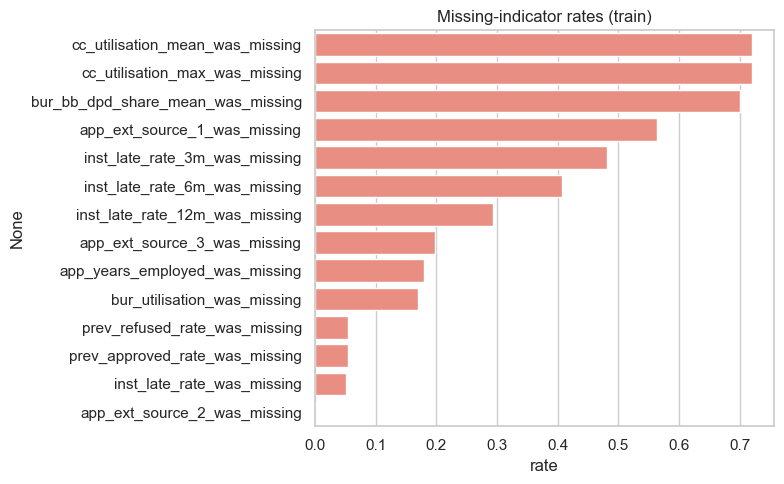

,rate
cc_utilisation_mean_was_missing,0.720526
cc_utilisation_max_was_missing,0.720526
bur_bb_dpd_share_mean_was_missing,0.700100
app_ext_source_1_was_missing,0.563956
inst_late_rate_3m_was_missing,0.480604
inst_late_rate_6m_was_missing,0.407923
inst_late_rate_12m_was_missing,0.292770
app_ext_source_3_was_missing,0.198004
app_years_employed_was_missing,0.180387
bur_utilisation_was_missing,0.169724


In [6]:
# Missing-indicator rates on train
flag_cols = [c for c in X_train_t.columns if c.endswith("_was_missing")]
rates = X_train_t[flag_cols].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=rates.values, y=rates.index, ax=ax, color="salmon")
ax.set_xlabel("rate")
ax.set_title("Missing-indicator rates (train)")
plt.tight_layout()
plt.show()
display(rates.to_frame("rate"))

In [7]:
# Fold-wise leakage check: fit preprocess on fold train, transform valid -- no NaNs
for fold in cv_folds[:2]:
    pipe = build_preprocess_pipeline(missing_cols)
    Xt = X.iloc[fold["train_idx"]]
    Xv = X.iloc[fold["valid_idx"]]
    pipe.fit(Xt)
    Xt_t = pipe.transform(Xt)
    Xv_t = pipe.transform(Xv)
    assert Xt_t.isna().sum().sum() == 0
    assert Xv_t.isna().sum().sum() == 0
    print(f"fold {fold['fold']}: transform ok, n_features={Xt_t.shape[1]}")
print("CV fold preprocess spot-check passed")


fold 0: transform ok, n_features=66
fold 1: transform ok, n_features=66
CV fold preprocess spot-check passed


## Save split indices

In [8]:
payload = {
    "random_seed": RANDOM_SEED,
    "holdout_size": HOLDOUT_SIZE,
    "n_cv_folds": N_CV_FOLDS,
    "n_rows": int(len(df)),
    "train_idx": train_idx.tolist(),
    "holdout_idx": holdout_idx.tolist(),
    "cv_folds": cv_folds,
    "feature_cols": feature_cols,
    "high_signal_missing": missing_cols,
    "train_target_rate": float(y.iloc[train_idx].mean()),
    "holdout_target_rate": float(y.iloc[holdout_idx].mean()),
}

SPLIT_INDICES_PATH.parent.mkdir(parents=True, exist_ok=True)
SPLIT_INDICES_PATH.write_text(json.dumps(payload), encoding="ascii")
print("wrote", SPLIT_INDICES_PATH)
print("train", len(payload["train_idx"]), "holdout", len(payload["holdout_idx"]))
print("cv folds", len(payload["cv_folds"]))


wrote C:\Users\user\Desktop\Credit-Scoring Project\data\processed\split_indices.json
train 246005 holdout 61502
cv folds 5


## Summary

- Stratified 80/20 holdout; target rates matched across splits.
- Stratified 5-fold CV indices on the train partition only.
- Preprocess via `src.preprocess` (missing indicators -> median impute -> p01/p99 cap).
- All fitting on train / fold-train only; holdout and fold-valid are transform-only.
- Production entrypoint: `python -m src.preprocess` (also `make preprocess`).
